In [ ]:
from google.colab import files

uploaded = files.upload()


In [ ]:
import os

os.listdir()

['.config', 'boston.csv', 'archive.zip', 'sample_data']

In [ ]:
!unzip -q archive.zip

replace boston.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
import pandas as pd

df = pd.read_csv('boston.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


In [ ]:
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [ ]:
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

print(X)
print(y)

        CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD    TAX  \
0    0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296.0   
1    0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242.0   
2    0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242.0   
3    0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222.0   
4    0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222.0   
..       ...   ...    ...   ...    ...    ...   ...     ...  ...    ...   
501  0.06263   0.0  11.93     0  0.573  6.593  69.1  2.4786    1  273.0   
502  0.04527   0.0  11.93     0  0.573  6.120  76.7  2.2875    1  273.0   
503  0.06076   0.0  11.93     0  0.573  6.976  91.0  2.1675    1  273.0   
504  0.10959   0.0  11.93     0  0.573  6.794  89.3  2.3889    1  273.0   
505  0.04741   0.0  11.93     0  0.573  6.030  80.8  2.5050    1  273.0   

     PTRATIO       B  LSTAT  
0       15.3  396.90   4.98  
1       17.8  396.90   9.14  
2       1

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(X_train.shape)
print(X_test.shape)

(354, 13)
(152, 13)


In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

comparison = pd.DataFrame({'Actual' : y_test, 'Predicted' : y_pred})
print(comparison)
#print(y_pred)

     Actual  Predicted
173    23.6  28.648960
274    32.4  36.495014
491    13.6  15.411193
72     22.8  25.403213
452    16.1  18.855280
..      ...        ...
441    17.1  17.403672
23     14.5  13.385941
225    50.0  39.983425
433    14.3  16.682863
447    12.6  18.285618

[152 rows x 2 columns]


In [ ]:
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error, mean_absolute_error

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
rsme = root_mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Root Mean Squared Error:", rsme)
print("Mean Squared Error:", mse)
print("R-squared:", r2)


Mean Absolute Error: 3.1627098714574013
Root Mean Squared Error: 4.638689926172818
Mean Squared Error: 21.517444231177183
R-squared: 0.7112260057484936


In [ ]:
print("Duplicated: ", df.duplicated().sum())

Duplicated:  0


In [ ]:
X.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000


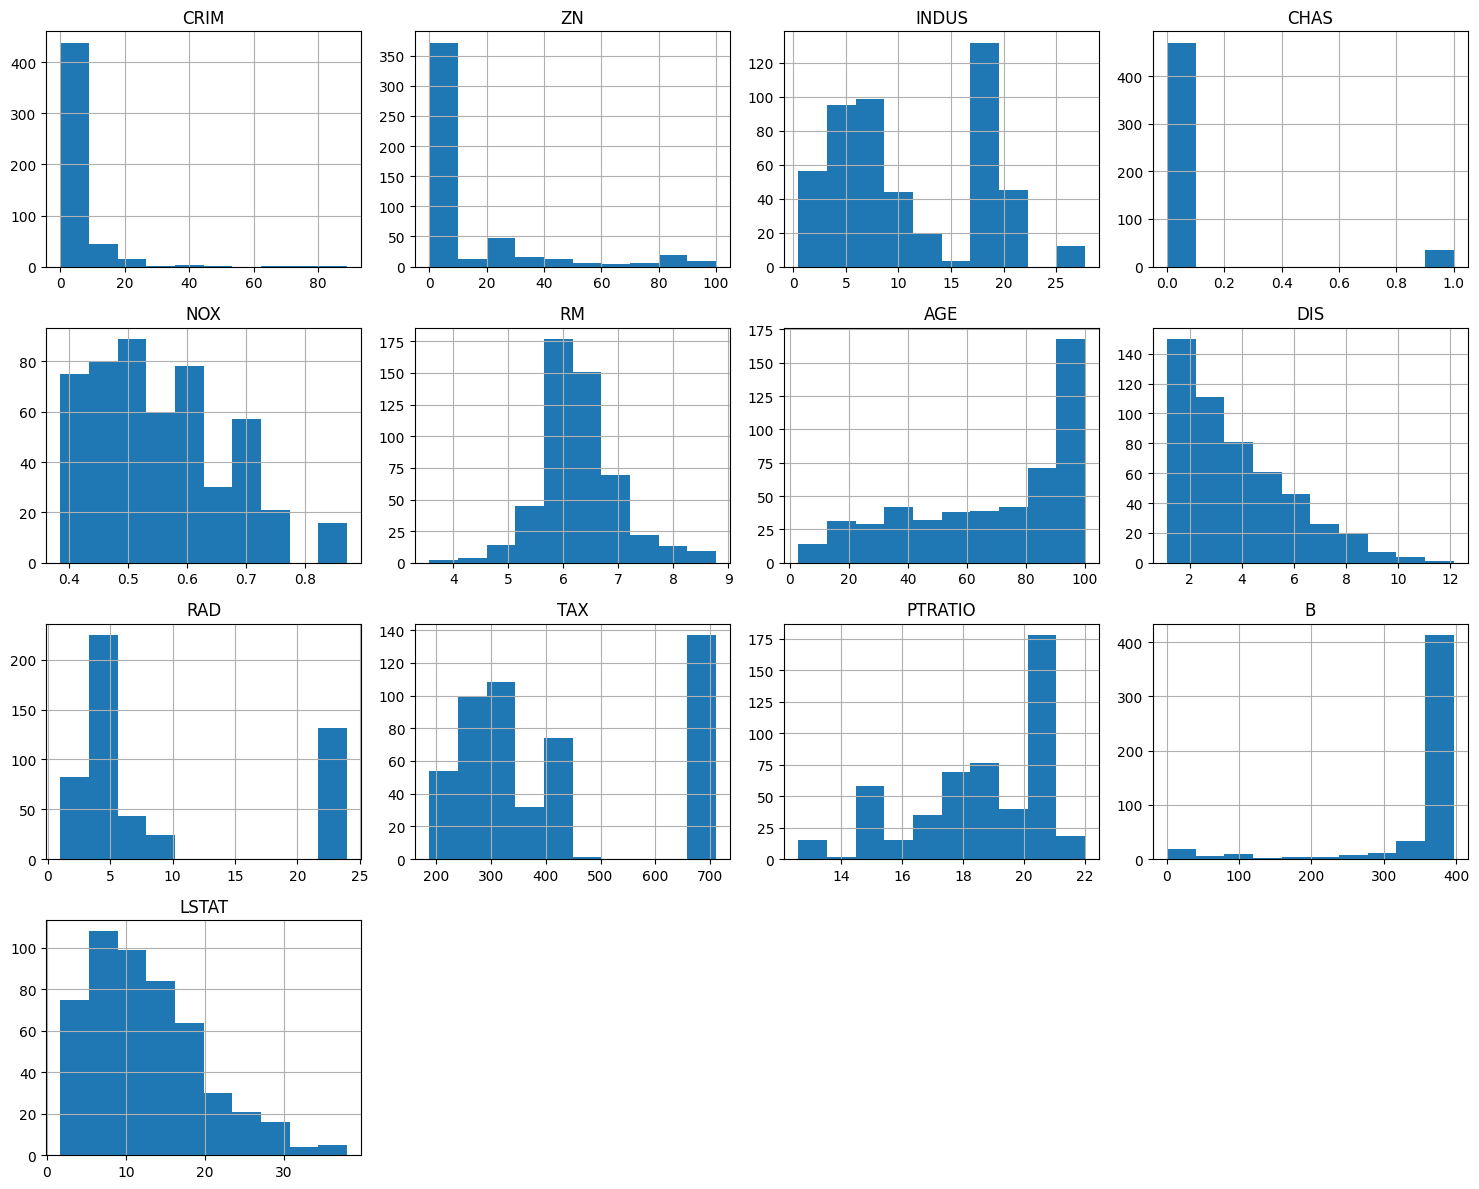

In [ ]:
import matplotlib.pyplot as plt

X.hist(figsize = (15, 12))
plt.tight_layout()
plt.show()

In [ ]:
print(model.coef_)

[-1.33470103e-01  3.58089136e-02  4.95226452e-02  3.11983512e+00
 -1.54170609e+01  4.05719923e+00 -1.08208352e-02 -1.38599824e+00
  2.42727340e-01 -8.70223437e-03 -9.10685208e-01  1.17941159e-02
 -5.47113313e-01]


In [ ]:
print(model.intercept_)

31.631084035693327


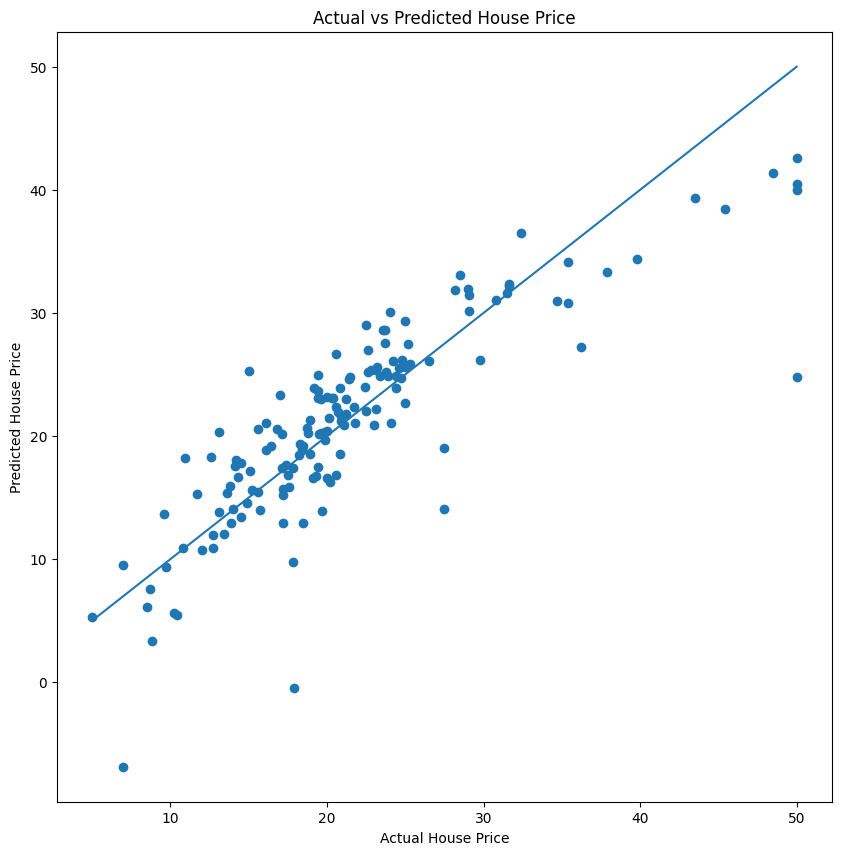

In [ ]:
plt.figure(figsize = (10, 10))
plt.scatter(y_test, y_pred)

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()])

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Price")
plt.show()


173   -5.048960
274   -4.095014
491   -1.811193
72    -2.603213
452   -2.755280
Name: MEDV, dtype: float64


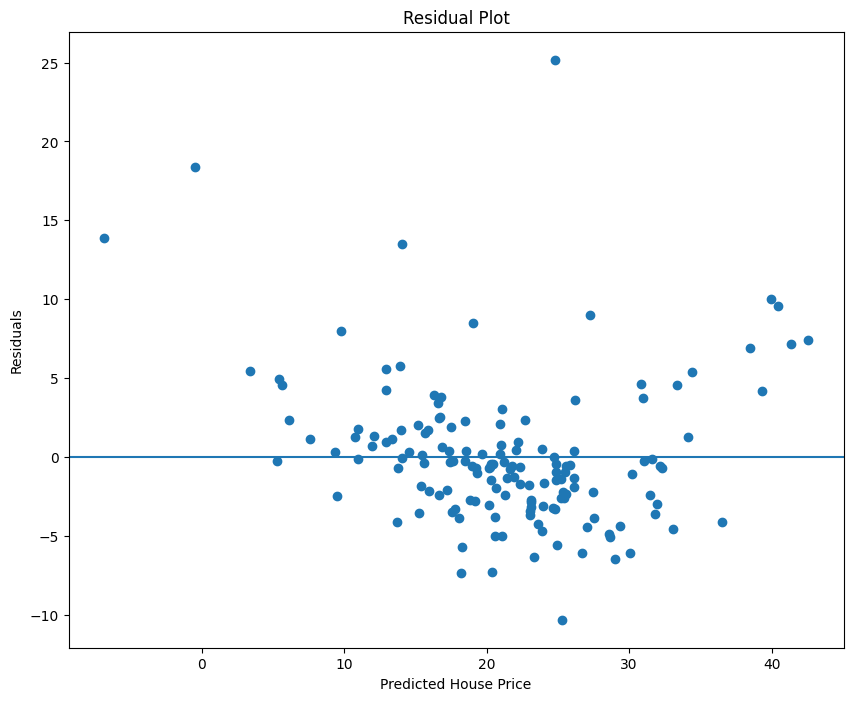

In [ ]:
#Residuals
residuals = y_test - y_pred
print(residuals.head())

plt.figure(figsize = (10, 8))
plt.scatter(y_pred, residuals)

plt.axhline(y = 0)

plt.xlabel("Predicted House Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

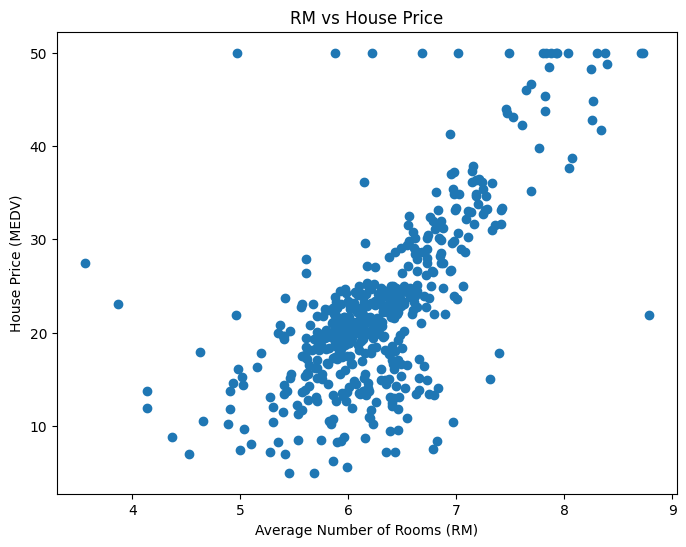

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(df["RM"], df["MEDV"])

plt.xlabel("Average Number of Rooms (RM)")
plt.ylabel("House Price (MEDV)")
plt.title("RM vs House Price")

plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler

scalar = StandardScaler()

X_train_scaled = scalar.fit_transform(X_train)
X_test_scaled = scalar.transform(X_test)

print(X_train_scaled[:5])

[[-0.41425879 -0.50512499 -1.29214218 -0.28154625 -0.85108479  0.14526384
  -0.365584    1.08162833 -0.74617905 -1.11279004  0.18727079  0.39651419
  -1.01531611]
 [-0.40200818 -0.50512499 -0.16208345 -0.28154625 -0.08796708 -0.20840082
   0.13394078 -0.48787608 -0.39846419  0.15008778 -0.21208981  0.3870674
  -0.05366252]
 [-0.39721053 -0.50512499 -0.60948856 -0.28154625 -0.93682836 -0.89623682
  -1.26690045  0.62859591 -0.74617905 -1.0466393  -0.16771641  0.42854113
  -0.31132373]
 [-0.29093623 -0.50512499 -0.43196976 -0.28154625 -0.16513629 -0.54396454
  -1.42978896  0.3451327  -0.6302741  -0.60162521  1.20785901  0.31276028
  -0.82242219]
 [ 1.45781561 -0.50512499  1.00549958 -0.28154625  0.19498668 -0.55649596
   0.07964461 -0.40389221  1.68782492  1.5572945   0.8528718   0.10412434
   0.8038002 ]]


In [ ]:
scaled_model = LinearRegression()

scaled_model.fit(X_train_scaled, y_train)

scaled_y_pred = scaled_model.predict(X_test_scaled)

print("R_Square: ", scaled_model.score(X_test_scaled, y_test))

R_Square:  0.7112260057484932


In [ ]:
print("Original R²:", model.score(X_test, y_test))
print("Scaled R²:", scaled_model.score(X_test_scaled, y_test))

Original R²: 0.7112260057484936
Scaled R²: 0.7112260057484932


In [ ]:
correlation = X.corr()
print(correlation["RM"].sort_values(ascending = False))

RM         1.000000
ZN         0.311991
DIS        0.205246
B          0.128069
CHAS       0.091251
RAD       -0.209847
CRIM      -0.219247
AGE       -0.240265
TAX       -0.292048
NOX       -0.302188
PTRATIO   -0.355501
INDUS     -0.391676
LSTAT     -0.613808
Name: RM, dtype: float64


In [ ]:
correlation = X.corr()

print(correlation.round(2))

         CRIM    ZN  INDUS  CHAS   NOX    RM   AGE   DIS   RAD   TAX  PTRATIO  \
CRIM     1.00 -0.20   0.41 -0.06  0.42 -0.22  0.35 -0.38  0.63  0.58     0.29   
ZN      -0.20  1.00  -0.53 -0.04 -0.52  0.31 -0.57  0.66 -0.31 -0.31    -0.39   
INDUS    0.41 -0.53   1.00  0.06  0.76 -0.39  0.64 -0.71  0.60  0.72     0.38   
CHAS    -0.06 -0.04   0.06  1.00  0.09  0.09  0.09 -0.10 -0.01 -0.04    -0.12   
NOX      0.42 -0.52   0.76  0.09  1.00 -0.30  0.73 -0.77  0.61  0.67     0.19   
RM      -0.22  0.31  -0.39  0.09 -0.30  1.00 -0.24  0.21 -0.21 -0.29    -0.36   
AGE      0.35 -0.57   0.64  0.09  0.73 -0.24  1.00 -0.75  0.46  0.51     0.26   
DIS     -0.38  0.66  -0.71 -0.10 -0.77  0.21 -0.75  1.00 -0.49 -0.53    -0.23   
RAD      0.63 -0.31   0.60 -0.01  0.61 -0.21  0.46 -0.49  1.00  0.91     0.46   
TAX      0.58 -0.31   0.72 -0.04  0.67 -0.29  0.51 -0.53  0.91  1.00     0.46   
PTRATIO  0.29 -0.39   0.38 -0.12  0.19 -0.36  0.26 -0.23  0.46  0.46     1.00   
B       -0.39  0.18  -0.36  

Archive:  archive.zip
  inflating: boston.csv              


In [ ]:

from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, include_bias=False)

X_rm = df[["RM"]]

X_rm_poly = poly.fit_transform(X_rm)

print(X_rm_poly[:5])

[[ 6.575    43.230625]
 [ 6.421    41.229241]
 [ 7.185    51.624225]
 [ 6.998    48.972004]
 [ 7.147    51.079609]]
